# Problem 4

In [73]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

from sklearn.metrics import mean_squared_error
import numpy as np

from ISLP import load_data

College = load_data('College')

In [74]:
# 4a
X = College.select_dtypes(include=[np.number]).drop("Apps", axis=1)
y = College['Apps']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [75]:
# 4b
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
mean_squared_error(y_test, y_pred)

np.float64(691695.2291394008)

In [76]:
# 4c
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RidgeCV(alphas=[0.01, 0.1, 1, 10, 100, 1000]))
])
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
mean_squared_error(y_test, y_pred)

np.float64(691734.2183136111)

In [77]:
# 4d
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LassoCV(alphas=[0.01, 0.1, 1, 10, 100, 1000]))
])
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
nonzero = np.sum(np.abs(pipeline['model'].coef_) > 1e-5)
mean_squared_error(y_test, y_pred), nonzero

(np.float64(729407.5304312743), np.int64(13))

In [78]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2)),
    ('model', LinearRegression())
])

grid = GridSearchCV(
    pipeline, 
    param_grid={'pca__n_components': np.arange(X.shape[1]) + 1}, 
    scoring='neg_mean_squared_error'
)
grid.fit(X_train, y_train)

y_pred = grid.predict(X_test)
mean_squared_error(y_test, y_pred), grid.best_params_

(np.float64(691695.2291393969), {'pca__n_components': np.int64(16)})

# Problem 7

In [79]:
import numpy as np
import matplotlib.pyplot as plt

In [80]:
# 7a
X1 = np.random.normal(10, 3, 100)
X2 = np.random.normal(5, 2, 100)
e = np.random.normal(0, 1, 100)

Y = 1 + 2 * X1 + 3 * X2 + e

In [81]:
Y

array([44.47825058, 21.94841785, 40.85215367, 26.84101318, 29.14413189,
       40.64520221, 34.11217133, 28.83220145, 39.5475929 , 42.49681772,
       43.5609312 , 58.80931015, 45.58891885, 33.95362034, 42.87112216,
       27.58492508, 33.89962414, 36.42474651, 29.5367868 , 39.23363175,
       38.90419694, 43.0042126 , 26.40801443, 31.06469618, 29.19641328,
       23.97339362, 45.12914089, 20.02657427, 35.70269314, 40.10407373,
       38.83596776, 27.28838574, 42.13837244, 34.50172847, 29.61307253,
       37.65752832, 32.10382847, 36.89100514, 39.00910573, 27.58455415,
       24.10309759, 33.09370751, 35.44954633, 38.0618909 , 55.03575236,
       47.54448728, 28.74075404, 38.80182944, 36.05695565, 37.6129522 ,
       27.70595712, 47.02972392, 35.47601661, 37.55171781, 37.8597678 ,
       31.63119163, 31.41117547, 31.71522275, 31.61694139, 37.26251609,
       43.05466515, 36.42832315, 51.58993915, 28.62247673, 35.30393559,
       31.829487  , 26.79379566, 42.71148939, 36.77378701, 32.39

In [82]:
# 7b
def simple_reg(outcome, feature):
    model = LinearRegression()
    model.fit(feature.reshape(-1, 1), outcome)
    return model.coef_[0], model.intercept_

In [83]:
# 7c
B1 = 0

In [84]:
# 7d
B2, B0 = simple_reg(Y - B1 * X1, X2)

In [85]:
# 7e
B1, B0 = simple_reg(Y - B2 * X2, X1)

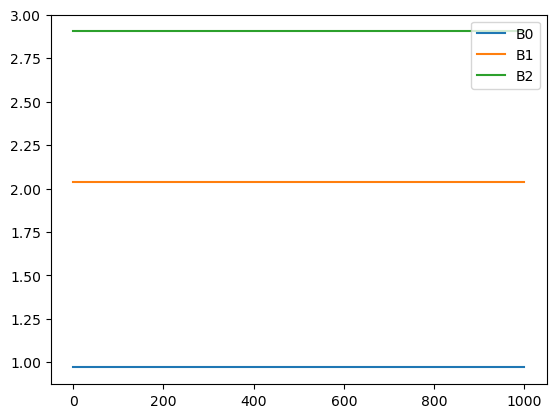

(np.float64(0.9697475425916906),
 np.float64(2.039282920837218),
 np.float64(2.9044349847297006))

In [87]:
# 7f

B0s, B1s, B2s = [B0], [B1], [B2]
for i in range(1000):
    B2, B0 = simple_reg(Y - B1 * X1, X2)
    B1, B0 = simple_reg(Y - B2 * X2, X1)
    B0s.append(B0)
    B1s.append(B1)
    B2s.append(B2)

plt.plot(B0s, label='B0')
plt.plot(B1s, label='B1')
plt.plot(B2s, label='B2')
plt.legend()
plt.show()

B0s[-1], B1s[-1], B2s[-1]